# Uso, procesamiento y visualización de grandes volúmenes de datos

## Predicción de lluvia al día siguiente con PySpark MLlib

**Materia:** Inteligencia Artificial Avanzada para la Ciencia de Datos  
**Estudiante:** Aron Cortez Villafuerte

### Planteamiento

En este trabajo analizo observaciones meteorológicas diarias del *Global Historical Climatology Network* (GHCN-Daily), publicado por NOAA. El objetivo es estimar si una estación registrará al menos 1 mm de precipitación al día siguiente. El umbral es una definición operativa del ejercicio y no pretende sustituir una categoría meteorológica oficial.

Tomé el periodo 2019–2025 porque sus siete archivos anuales suman 1.214 GB comprimidos. El volumen proviene de archivos originales de NOAA y no de repetir datos. La lectura, el control de calidad y las agregaciones se realizan sobre 263,439,252 registros. Para el modelo uso una fracción reproducible de estaciones y una muestra balanceada de entrenamiento, ya que la validación cruzada ajusta doce modelos y Colab funciona en una sola máquina.

El diseño conserva 2025 como prueba temporal. Ningún registro de ese año interviene en el ajuste ni en la selección de hiperparámetros. Así, la evaluación se parece más a una predicción futura que una división aleatoria de observaciones del mismo periodo.

## 1. Configuración del ambiente

La primera celda instala las bibliotecas sólo cuando hacen falta. Después crea una sesión local de Spark y fija un número moderado de particiones. Colab no es un clúster de producción, pero conserva el modelo de ejecución distribuida de Spark: las transformaciones se construyen primero y se materializan cuando se solicita una acción.

In [3]:
import sys, subprocess, importlib.util

required = {
    "pyspark": "pyspark==4.0.1",
    "pyarrow": "pyarrow>=15",
    "seaborn": "seaborn>=0.13",
    "sklearn": "scikit-learn>=1.4",
}
missing = [pkg for module, pkg in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
print("Dependencias listas")

Dependencias listas


In [4]:
import json, math, os, shutil, platform
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed
from urllib.request import Request, urlopen

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql import SparkSession, Window, functions as F, types as T
from pyspark.storagelevel import StorageLevel

IN_COLAB = "google.colab" in sys.modules
BASE_DIR = Path("/content/ghcn_daily" if IN_COLAB else "work/ghcn/data")
YEAR_DIR = BASE_DIR / "by_year"
EXPORT_DIR = Path("/content/entregables" if IN_COLAB else "outputs/GHCN_Daily")
YEAR_DIR.mkdir(parents=True, exist_ok=True)
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

spark = (
    SparkSession.builder
    .appName("GHCN-Daily-BigData-MLlib")
    .master("local[*]")
    .config("spark.driver.memory", "6g" if IN_COLAB else "10g")
    .config("spark.sql.shuffle.partitions", "96")
    .config("spark.sql.adaptive.enabled", "true")
    .config("spark.sql.execution.arrow.pyspark.enabled", "true")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")
print("Python:", platform.python_version())
print("Spark:", spark.version)
print("Núcleos lógicos:", os.cpu_count())
print("Directorio de datos:", YEAR_DIR.resolve())

Python: 3.12.10
Spark: 4.2.0
Núcleos lógicos: 12
Directorio de datos: work/ghcn/data/by_year


## 2. Fuente y volumen

GHCN-Daily integra observaciones de más de 100,000 estaciones en 180 países y territorios. NOAA publica los archivos anuales, el catálogo de estaciones y el diccionario del formato sin exigir credenciales. Las variables usadas son precipitación (`PRCP`), temperatura máxima (`TMAX`) y temperatura mínima (`TMIN`).

La [descripción del producto](https://www.ncei.noaa.gov/products/land-based-station/global-historical-climatology-network-daily), el [formato anual](https://www.ncei.noaa.gov/pub/data/ghcn/daily/readme-by_year.txt) y el [índice de descargas](https://www.ncei.noaa.gov/pub/data/ghcn/daily/by_year/) permiten verificar la procedencia. La descarga comprueba cada archivo y detiene el proceso si el total no supera 1 GB.

2019.csv.gz: 163.8 MiB
2020.csv.gz: 164.5 MiB
2021.csv.gz: 167.3 MiB
2022.csv.gz: 167.6 MiB
2023.csv.gz: 167.9 MiB
2024.csv.gz: 168.4 MiB
2025.csv.gz: 158.4 MiB

Archivos anuales: 7
Volumen comprimido: 1.214 GB (1.131 GiB)


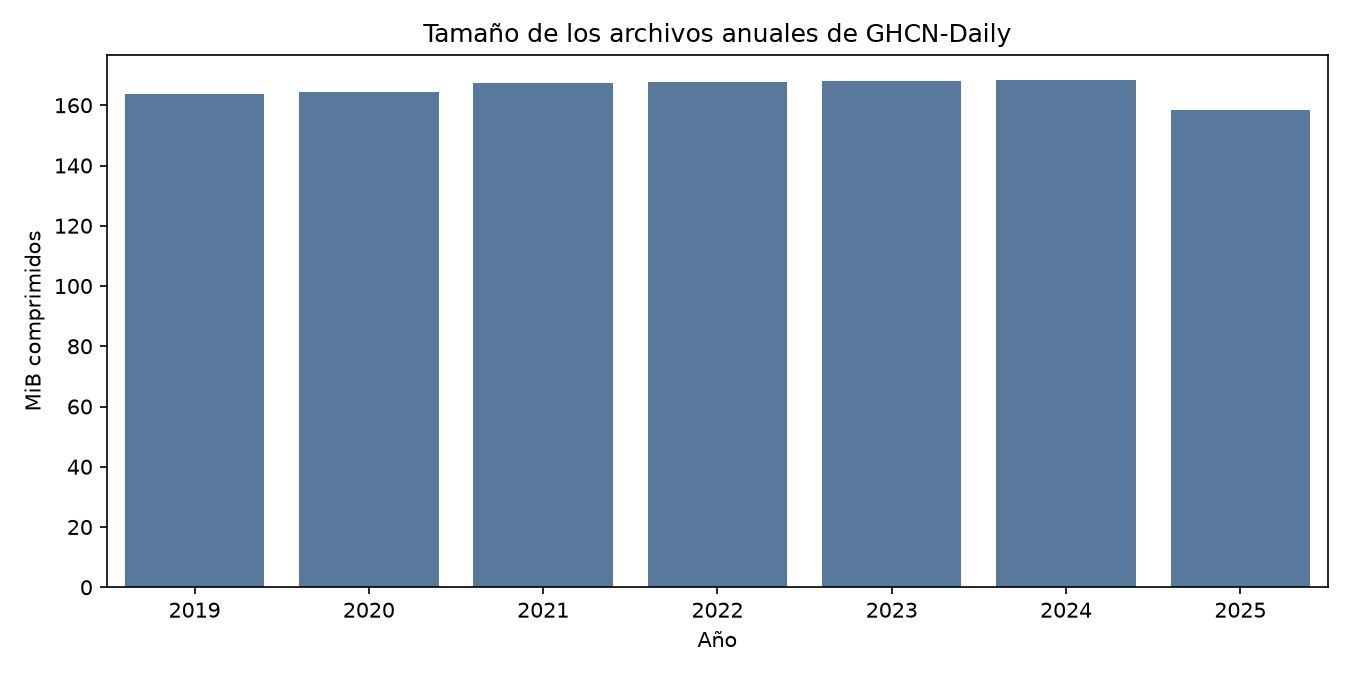

In [6]:
YEARS = list(range(2019, 2026))
BASE_URL = "https://www.ncei.noaa.gov/pub/data/ghcn/daily"

def download(url, target, minimum_bytes=1):
    if target.exists() and target.stat().st_size >= minimum_bytes:
        return target.name, target.stat().st_size, "existente"
    temp = target.with_suffix(target.suffix + ".part")
    request = Request(url, headers={"User-Agent": "Mozilla/5.0 academic project"})
    with urlopen(request, timeout=300) as response, open(temp, "wb") as destination:
        shutil.copyfileobj(response, destination, length=8 * 1024 * 1024)
    temp.replace(target)
    return target.name, target.stat().st_size, "descargado"

jobs = [
    (f"{BASE_URL}/by_year/{year}.csv.gz", YEAR_DIR / f"{year}.csv.gz", 100_000_000)
    for year in YEARS
]
jobs += [
    (f"{BASE_URL}/ghcnd-stations.txt", BASE_DIR / "ghcnd-stations.txt", 1_000_000),
    (f"{BASE_URL}/ghcnd-countries.txt", BASE_DIR / "ghcnd-countries.txt", 1_000),
]

with ThreadPoolExecutor(max_workers=4) as pool:
    for name, size, status in [future.result() for future in [pool.submit(download, *job) for job in jobs]]:
        print(f"{name}: {size/1024**2:,.1f} MiB ({status})")

files = [YEAR_DIR / f"{year}.csv.gz" for year in YEARS]
total_bytes = sum(path.stat().st_size for path in files)
print(f"\nArchivos anuales: {len(files)}")
print(f"Volumen comprimido: {total_bytes/1e9:,.3f} GB ({total_bytes/1024**3:,.3f} GiB)")
assert len(files) == 7 and total_bytes >= 1_000_000_000

## 3. Lectura distribuida y control de calidad

El formato anual tiene una fila por estación, fecha y elemento. Defino el esquema en lugar de pedirle a Spark que lo infiera sobre 1.2 GB. Después conservo las tres variables del estudio y retiro las observaciones marcadas por NOAA con una bandera de calidad. Esta decisión evita mezclar valores rechazados con mediciones válidas.

El conteo completo es una acción de Spark y obliga a recorrer los siete archivos. De 263.4 millones de registros originales, 140.3 millones corresponden a precipitación o temperatura y pasan el filtro de calidad.

In [8]:
schema = T.StructType([
    T.StructField("station_id", T.StringType(), False),
    T.StructField("date_raw", T.StringType(), False),
    T.StructField("element", T.StringType(), False),
    T.StructField("data_value", T.DoubleType(), True),
    T.StructField("m_flag", T.StringType(), True),
    T.StructField("q_flag", T.StringType(), True),
    T.StructField("s_flag", T.StringType(), True),
    T.StructField("obs_time", T.StringType(), True),
])

raw = spark.read.schema(schema).option("header", False).csv([str(path) for path in files])
total_rows = raw.count()

valid = (
    raw.filter(F.col("element").isin("PRCP", "TMAX", "TMIN"))
    .filter(F.col("q_flag").isNull() | (F.trim("q_flag") == ""))
    .withColumn("date", F.to_date("date_raw", "yyyyMMdd"))
    .select("station_id", "date", "element", "data_value")
    .persist(StorageLevel.DISK_ONLY)
)
valid_rows = valid.count()
print(f"Registros originales: {total_rows:,}")
print(f"Observaciones meteorológicas válidas: {valid_rows:,}")
valid.show(5, truncate=False)

Registros originales: 263,439,252
Observaciones meteorológicas válidas: 140,345,668
+-----------+----------+-------+----------+
|station_id |date      |element|data_value|
+-----------+----------+-------+----------+
|AE000041196|2019-01-01|TMAX   |278.0     |
|AE000041196|2019-01-01|TMIN   |178.0     |
|AE000041196|2019-01-01|PRCP   |0.0       |
+-----------+----------+-------+----------+


## 4. Metadatos y capa para Tableau

El catálogo de estaciones aporta país, latitud, longitud y elevación. Para el tablero no exporto los 140 millones de registros válidos. Spark los resume por mes, país y cuadrícula de cuatro grados. Esta granularidad conserva los patrones geográficos y temporales, pero reduce la salida a 117,590 filas que Tableau puede manejar con fluidez.

El número de observaciones mide cobertura, no intensidad de lluvia. Una región con más estaciones aparecerá con más registros aunque su precipitación sea menor. Por eso el tablero separa cobertura, proporción de días lluviosos y precipitación media.

Filas de la capa Tableau: 117,590


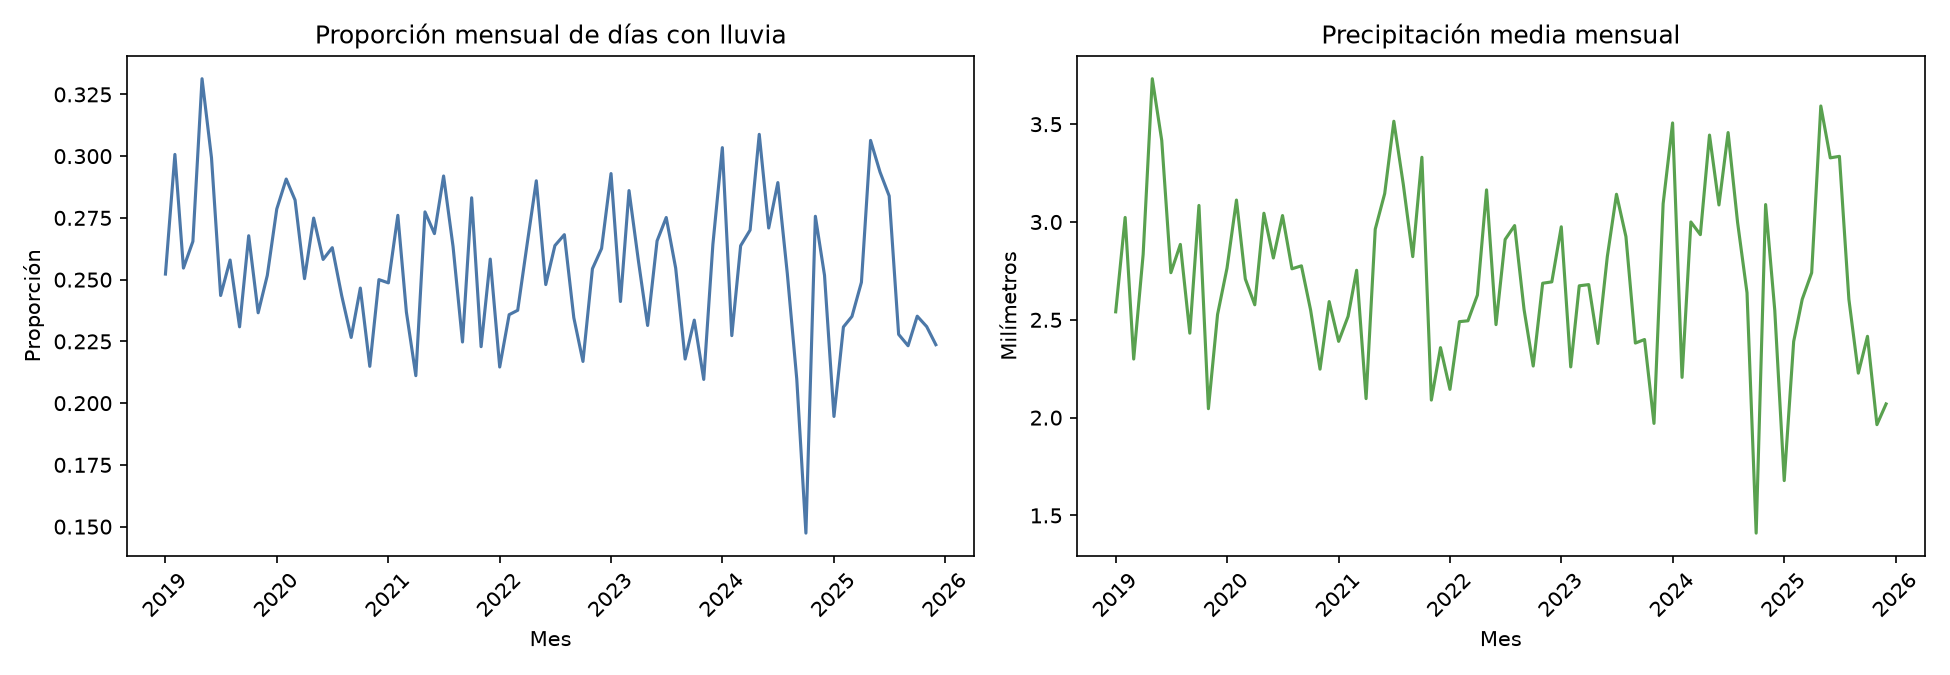

In [10]:
station_cols = ["station_id", "latitude", "longitude", "elevation", "state", "station_name",
                "gsn_flag", "hcn_crn_flag", "wmo_id"]
stations_pd = pd.read_fwf(
    BASE_DIR / "ghcnd-stations.txt",
    colspecs=[(0,11),(12,20),(21,30),(31,37),(38,40),(41,71),(72,75),(76,79),(80,85)],
    names=station_cols,
)
countries_pd = pd.read_fwf(BASE_DIR / "ghcnd-countries.txt", colspecs=[(0,2),(3,64)],
                           names=["country_code", "country_name"])
stations_pd["country_code"] = stations_pd["station_id"].str[:2]
stations_pd = stations_pd.merge(countries_pd, on="country_code", how="left")
station_export = EXPORT_DIR / "metadata_estaciones.csv"
stations_pd[["station_id", "latitude", "longitude", "elevation", "country_code", "country_name"]].to_csv(
    station_export, index=False
)
station_schema = T.StructType([
    T.StructField("station_id", T.StringType(), False),
    T.StructField("latitude", T.DoubleType(), True),
    T.StructField("longitude", T.DoubleType(), True),
    T.StructField("elevation", T.DoubleType(), True),
    T.StructField("country_code", T.StringType(), True),
    T.StructField("country_name", T.StringType(), True),
])
stations = spark.read.schema(station_schema).option("header", True).csv(str(station_export))

joined = (
    valid.join(F.broadcast(stations.select("station_id", "latitude", "longitude", "elevation",
                                           "country_code", "country_name")), "station_id", "left")
    .withColumn("year", F.year("date"))
    .withColumn("month", F.month("date"))
    .withColumn("lat_grid", F.round(F.col("latitude") / 4) * 4)
    .withColumn("lon_grid", F.round(F.col("longitude") / 4) * 4)
)

dashboard = (
    joined.groupBy("year", "month", "country_code", "country_name", "lat_grid", "lon_grid")
    .agg(
        F.count("*").alias("observations"),
        F.countDistinct("station_id").alias("stations"),
        F.sum(F.when(F.col("element") == "PRCP", 1).otherwise(0)).alias("prcp_obs"),
        F.sum(F.when((F.col("element") == "PRCP") & (F.col("data_value") >= 10), 1).otherwise(0)).alias("rain_days"),
        F.avg(F.when(F.col("element") == "PRCP", F.col("data_value") / 10)).alias("avg_prcp_mm"),
        F.avg(F.when(F.col("element") == "TMAX", F.col("data_value") / 10)).alias("avg_tmax_c"),
        F.avg(F.when(F.col("element") == "TMIN", F.col("data_value") / 10)).alias("avg_tmin_c"),
    )
    .withColumn("rain_rate", F.col("rain_days") / F.col("prcp_obs"))
    .withColumn("month_start", F.make_date("year", "month", F.lit(1)))
    .withColumn("hemisphere", F.when(F.col("lat_grid") >= 0, "Norte").otherwise("Sur"))
)

tableau_columns = [
    "year", "month", "rain_days", "country_name", "country_code",
    "hemisphere", "observations", "avg_prcp_mm", "avg_tmin_c",
    "rain_rate", "prcp_obs", "avg_tmax_c", "month_start",
]
dashboard_pdf = dashboard.select(*tableau_columns).toPandas()
dashboard_pdf.to_csv(EXPORT_DIR / "tableau_ghcn_daily_2019_2025.csv", index=False)
print(f"Filas de la capa Tableau: {len(dashboard_pdf):,}")

## 5. Construcción de la variable objetivo

La etiqueta indica si la precipitación del día siguiente alcanza 1 mm. Para crearla uso `lead(PRCP, 1)` dentro de cada estación y conservo únicamente fechas consecutivas. Las entradas contienen precipitación actual, tres rezagos, temperaturas, rango térmico, ubicación, elevación y estacionalidad del día del año.

La precipitación del día objetivo no aparece entre los predictores. También verifico la continuidad de los cuatro días previos para que un rezago no represente una fecha distante. El procesamiento completo produce 4,218,159 secuencias aptas en la fracción reproducible de estaciones.

In [12]:
model_long = joined.filter(F.pmod(F.xxhash64("station_id"), F.lit(100)) < 6)
daily = (
    model_long.groupBy("station_id", "date", "latitude", "longitude", "elevation", "country_name")
    .agg(
        F.max(F.when(F.col("element") == "PRCP", F.col("data_value") / 10)).alias("prcp_mm"),
        F.max(F.when(F.col("element") == "TMAX", F.col("data_value") / 10)).alias("tmax_c"),
        F.max(F.when(F.col("element") == "TMIN", F.col("data_value") / 10)).alias("tmin_c"),
    )
    .filter(F.col("prcp_mm").isNotNull())
)
w = Window.partitionBy("station_id").orderBy("date")
modeled = (
    daily
    .withColumn("date_lag1", F.lag("date", 1).over(w))
    .withColumn("date_lag2", F.lag("date", 2).over(w))
    .withColumn("date_lag3", F.lag("date", 3).over(w))
    .withColumn("target_date", F.lead("date", 1).over(w))
    .withColumn("prcp_lag1", F.lag("prcp_mm", 1).over(w))
    .withColumn("prcp_lag2", F.lag("prcp_mm", 2).over(w))
    .withColumn("prcp_lag3", F.lag("prcp_mm", 3).over(w))
    .withColumn("target_prcp_mm", F.lead("prcp_mm", 1).over(w))
    .filter(F.datediff("date", "date_lag1") == 1)
    .filter(F.datediff("date", "date_lag2") == 2)
    .filter(F.datediff("date", "date_lag3") == 3)
    .filter(F.datediff("target_date", "date") == 1)
    .withColumn("label", (F.col("target_prcp_mm") >= 1).cast("double"))
    .withColumn("temp_range", F.col("tmax_c") - F.col("tmin_c"))
    .withColumn("day_of_year", F.dayofyear("date").cast("double"))
    .withColumn("doy_sin", F.sin(F.lit(2 * math.pi) * F.col("day_of_year") / 365.25))
    .withColumn("doy_cos", F.cos(F.lit(2 * math.pi) * F.col("day_of_year") / 365.25))
    .withColumn("year", F.year("date"))
    .persist(StorageLevel.MEMORY_AND_DISK)
)
print(f"Secuencias aptas: {modeled.count():,}")

Secuencias aptas: 4,218,159


## 6. Separación temporal y muestra de entrenamiento

Los años 2019–2024 forman el bloque de entrenamiento. Balanceo esa muestra con alrededor de 150,000 casos por clase para que la regresión logística vea suficientes días lluviosos. La prueba usa 249,660 observaciones de 2025 con su frecuencia natural, por lo que sus métricas no se benefician del balanceo.

Este cambio de distribución importa. Una precisión alta en la muestra balanceada no equivale a la probabilidad real de lluvia. Por eso reporto AUC-PR y métricas específicas de la clase positiva en 2025.

Entrenamiento: 300,884
Prueba temporal 2025: 249,660
+-----+------+
|label| count|
+-----+------+
|  0.0|150595|
|  1.0|150289|
+-----+------+


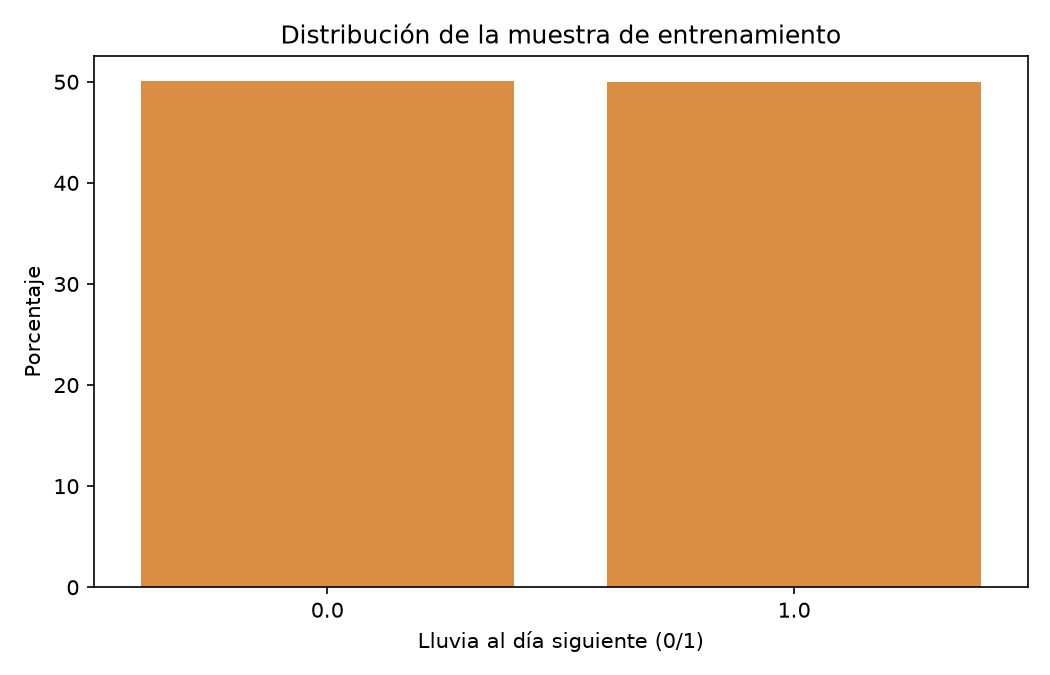

In [14]:
training_full = modeled.filter(F.col("year") <= 2024)
test_full = modeled.filter(F.col("year") == 2025)

counts = {int(row["label"]): int(row["count"]) for row in training_full.groupBy("label").count().collect()}
fractions = {float(label): min(1.0, 150_000 / count) for label, count in counts.items()}
train = training_full.sampleBy("label", fractions=fractions, seed=42).cache()

test_fraction = min(1.0, 250_000 / test_full.count())
test = test_full.sample(False, test_fraction, seed=43).cache()

print(f"Entrenamiento: {train.count():,}")
print(f"Prueba temporal 2025: {test.count():,}")
train.groupBy("label").count().orderBy("label").show()

## 7. Pipeline y validación cruzada

La regresión logística funciona como línea base interpretable para una respuesta binaria. El `Pipeline` conserva el mismo orden al entrenar y predecir: imputación por mediana, ensamblado, estandarización y clasificación.

El `CrossValidator` usa tres particiones y compara cuatro combinaciones de regularización. En total se ajustan doce modelos. La selección se hace con AUC-PR promedio porque la lluvia es minoritaria en la distribución natural. El conjunto de 2025 sigue aislado durante esta etapa.

 regParam  elasticNetParam  AUC_PR_CV
     0.10              0.5   0.667638
     0.01              0.5   0.660887
     0.01              0.0   0.659181
     0.10              0.0   0.652799

Mejor regParam: 0.1
Mejor elasticNetParam: 0.5


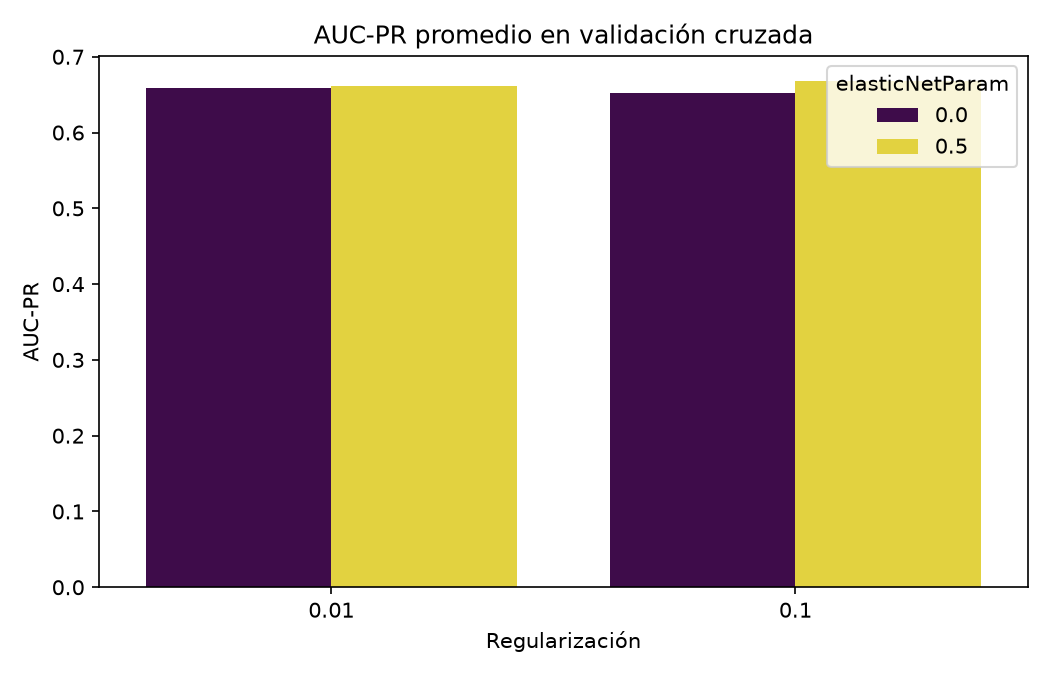

In [16]:
from pyspark.ml import Pipeline
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator
from pyspark.ml.feature import Imputer, StandardScaler, VectorAssembler
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder

FEATURES = ["prcp_mm", "prcp_lag1", "prcp_lag2", "prcp_lag3", "tmax_c", "tmin_c",
            "temp_range", "latitude", "longitude", "elevation", "doy_sin", "doy_cos"]
imputed = [f"{column}_imp" for column in FEATURES]

imputer = Imputer(inputCols=FEATURES, outputCols=imputed, strategy="median")
assembler = VectorAssembler(inputCols=imputed, outputCol="features_raw", handleInvalid="keep")
scaler = StandardScaler(inputCol="features_raw", outputCol="features", withMean=False, withStd=True)
lr = LogisticRegression(labelCol="label", featuresCol="features", maxIter=50, standardization=False)
pipeline = Pipeline(stages=[imputer, assembler, scaler, lr])

grid = (ParamGridBuilder()
        .addGrid(lr.regParam, [0.01, 0.10])
        .addGrid(lr.elasticNetParam, [0.0, 0.5])
        .build())
pr_eval = BinaryClassificationEvaluator(labelCol="label", metricName="areaUnderPR")
cv = CrossValidator(estimator=pipeline, estimatorParamMaps=grid, evaluator=pr_eval,
                    numFolds=3, parallelism=2, seed=42)
cv_model = cv.fit(train)

cv_rows = []
for params, metric in zip(cv_model.getEstimatorParamMaps(), cv_model.avgMetrics):
    cv_rows.append({"regParam": params[lr.regParam],
                    "elasticNetParam": params[lr.elasticNetParam],
                    "AUC_PR_CV": float(metric)})
cv_results = pd.DataFrame(cv_rows).sort_values("AUC_PR_CV", ascending=False)
display(cv_results)
print("Mejor regParam:", cv_model.bestModel.stages[-1].getRegParam())
print("Mejor elasticNetParam:", cv_model.bestModel.stages[-1].getElasticNetParam())

## 8. Evaluación en 2025

El mejor ajuste alcanzó AUC-PR de 0.668 durante la validación balanceada. En 2025 obtuvo AUC-ROC de 0.657 y AUC-PR de 0.394. La accuracy de 0.737 y el F1 ponderado de 0.730 parecen altos, pero están influidos por la mayoría de días sin lluvia.

La clase que interesa tiene precisión de 0.424 y recall de 0.366. En términos sencillos, el modelo identifica cerca de 37 de cada 100 días lluviosos y varias alertas resultan falsas. Existe una señal útil, sobre todo por la precipitación del día actual, pero no alcanza para tratarlo como un pronóstico meteorológico operativo.

               Métrica    Valor
               AUC-ROC 0.657113
                AUC-PR 0.393568
              Accuracy 0.736866
                    F1 0.729931
   Precisión ponderada 0.724490
      Recall ponderado 0.736866
Precisión clase lluvia 0.423698
   Recall clase lluvia 0.366144
       F1 clase lluvia 0.392824

 label  prediction  count
   0.0         0.0 162715
   0.0         1.0  28905
   1.0         0.0  36789
   1.0         1.0  21251


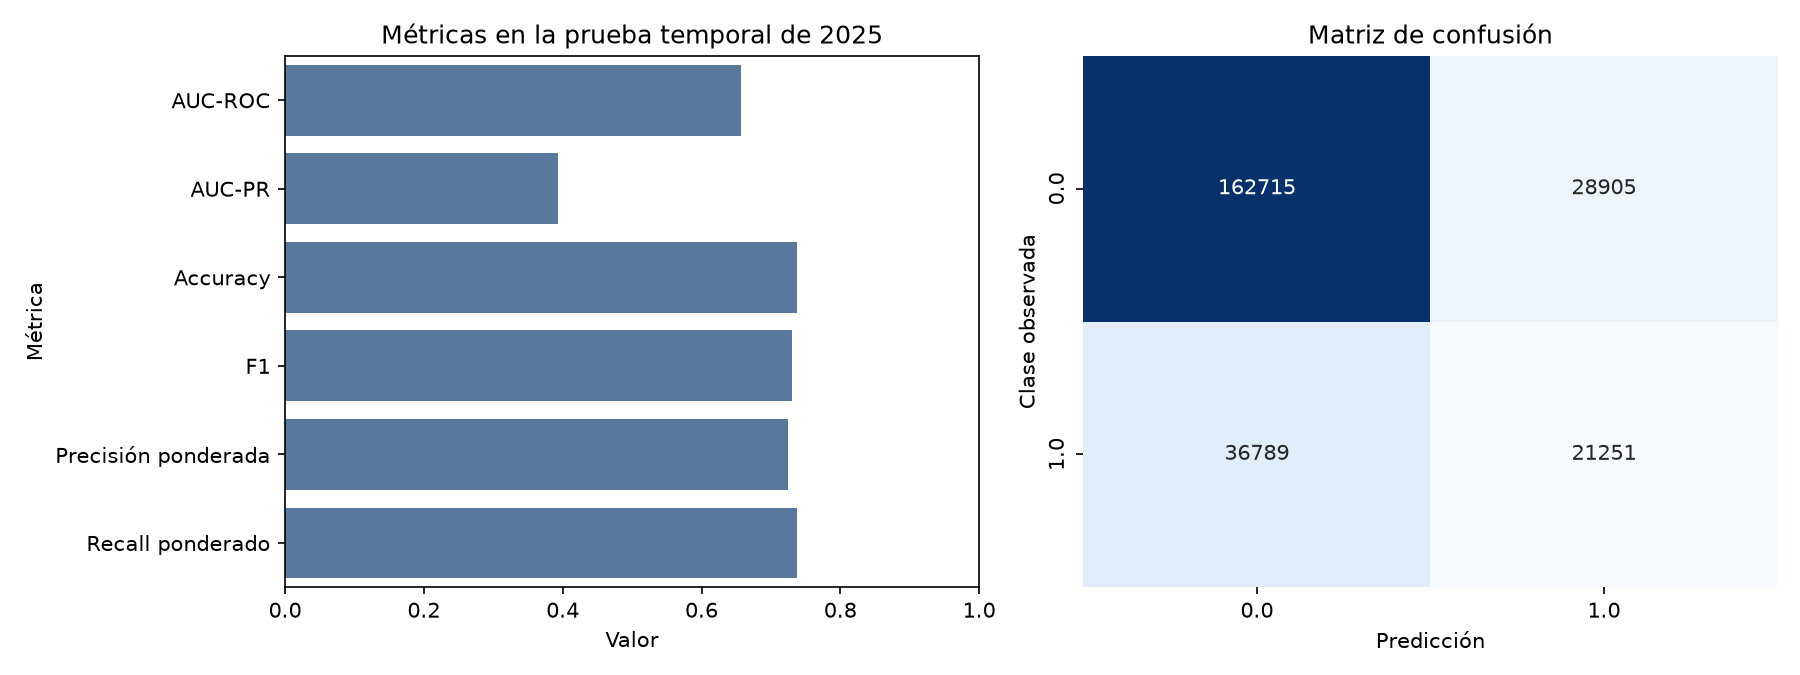

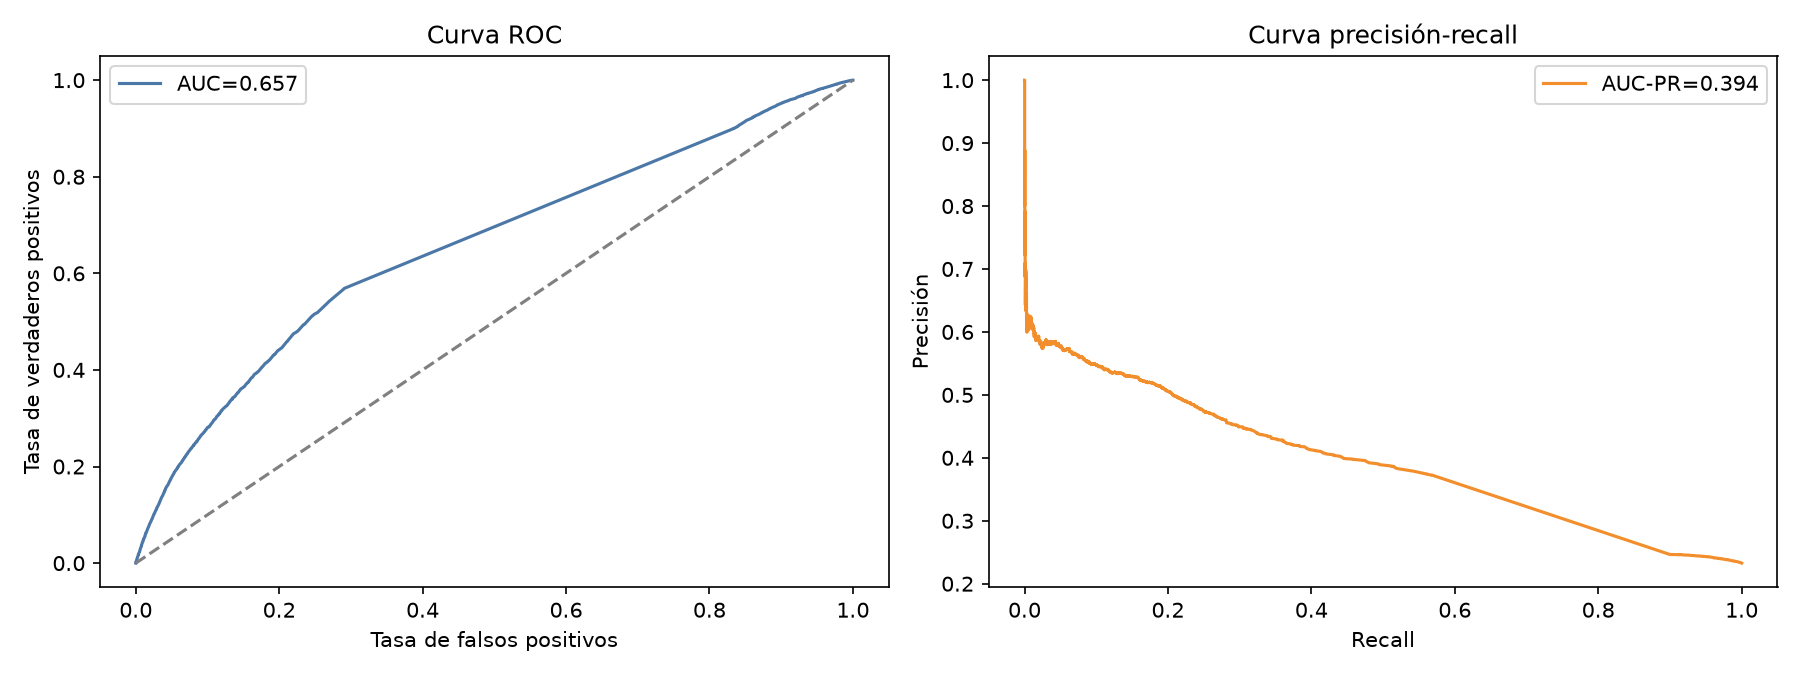

In [18]:
pred = cv_model.transform(test).cache()
evaluators = {
    "AUC-ROC": BinaryClassificationEvaluator(labelCol="label", metricName="areaUnderROC"),
    "AUC-PR": BinaryClassificationEvaluator(labelCol="label", metricName="areaUnderPR"),
    "Accuracy": MulticlassClassificationEvaluator(labelCol="label", metricName="accuracy"),
    "F1": MulticlassClassificationEvaluator(labelCol="label", metricName="f1"),
}
metrics = {name: evaluator.evaluate(pred) for name, evaluator in evaluators.items()}
confusion = pred.groupBy("label", "prediction").count().orderBy("label", "prediction")
confusion_map = {
    (int(row["label"]), int(row["prediction"])): int(row["count"])
    for row in confusion.collect()
}
tp = confusion_map.get((1, 1), 0)
fp = confusion_map.get((0, 1), 0)
fn = confusion_map.get((1, 0), 0)
precision_lluvia = tp / (tp + fp) if tp + fp else 0.0
recall_lluvia = tp / (tp + fn) if tp + fn else 0.0
f1_lluvia = (2 * precision_lluvia * recall_lluvia / (precision_lluvia + recall_lluvia)
             if precision_lluvia + recall_lluvia else 0.0)
metrics.update({
    "Precisión lluvia": precision_lluvia,
    "Recall lluvia": recall_lluvia,
    "F1 lluvia": f1_lluvia,
})
display(pd.DataFrame(metrics.items(), columns=["Métrica", "Valor"]))
confusion.show()

## 9. Predicciones sobre datos no vistos

Las siguientes filas pertenecen a 2025. La probabilidad es la salida de la regresión logística y la predicción aplica el umbral de 0.5. Incluyo la clase observada para distinguir aciertos y errores, no para usarla como entrada.

In [20]:
from pyspark.ml.functions import vector_to_array

prediction_examples = (
    pred.select(
        "station_id", "country_name", "date", "target_date", "label", "prediction",
        vector_to_array("probability")[1].alias("probabilidad_lluvia"),
        "prcp_mm", "prcp_lag1", "tmax_c", "tmin_c", "latitude", "longitude",
    )
    .orderBy(F.rand(seed=45))
    .limit(25)
)
display(prediction_examples.toPandas())
prediction_examples.toPandas().to_csv(EXPORT_DIR / "predicciones_ejemplo.csv", index=False)

 station_id  country_name       date target_date  label  prediction  probabilidad_lluvia  prcp_mm  prcp_lag1  tmax_c  tmin_c  latitude  longitude
US1GACU0009 United States 2025-09-21  2025-09-22    0.0         0.0             0.486473      0.0        0.0     NaN     NaN   33.5298   -82.2873
SWE00138040        Sweden 2025-08-31  2025-09-01    1.0         0.0             0.486473      0.0        8.5     NaN     NaN   57.3000    12.6900
US1KSJO0091 United States 2025-09-27  2025-09-28    0.0         0.0             0.486473      0.0        0.0     NaN     NaN   38.7697   -94.7867
USC00330676 United States 2025-12-14  2025-12-15    0.0         1.0             0.516652      8.1        0.0     1.7    -9.4   39.5475   -81.6283
USC00167732 United States 2025-09-07  2025-09-08    0.0         0.0             0.486473      0.0        0.0     NaN     NaN   31.1872   -92.2906
US1COPU0122 United States 2025-06-04  2025-06-05    1.0         1.0             0.507057      5.1       21.1     NaN     NaN

## 10. Interpretación del modelo

La regularización elástica dejó dos coeficientes distintos de cero. La precipitación del día actual tiene una asociación positiva con la lluvia del día siguiente. El rango térmico tiene una asociación negativa pequeña. Los demás coeficientes quedaron en cero para la combinación seleccionada.

Este resultado no implica causalidad. También muestra una limitación: con variables diarias y una regresión lineal en los parámetros, el modelo captura persistencia meteorológica básica, pero pierde relaciones espaciales y atmosféricas más complejas.

  variable  coeficiente  magnitud
   prcp_mm     0.155260  0.155260
temp_range    -0.051469  0.051469
 prcp_lag2     0.000000  0.000000
 prcp_lag1     0.000000  0.000000
 prcp_lag3     0.000000  0.000000
    tmax_c     0.000000  0.000000
    tmin_c     0.000000  0.000000
  latitude     0.000000  0.000000
 longitude     0.000000  0.000000
 elevation     0.000000  0.000000
   doy_sin     0.000000  0.000000
   doy_cos     0.000000  0.000000


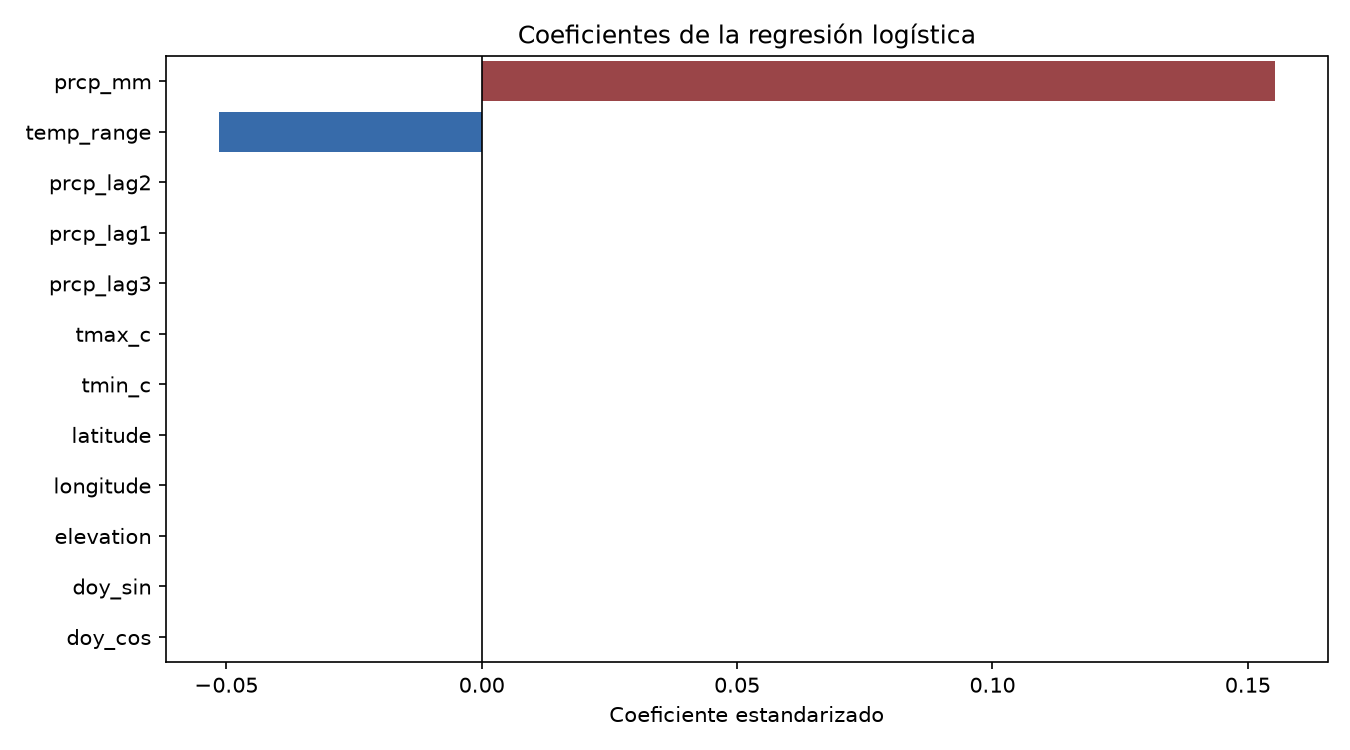

In [22]:
best_lr = cv_model.bestModel.stages[-1]
coef_df = pd.DataFrame({"variable": FEATURES, "coeficiente": best_lr.coefficients.toArray()})
coef_df["magnitud"] = coef_df["coeficiente"].abs()
display(coef_df.sort_values("magnitud", ascending=False))

## 11. Tablero de visualización

**Estado de publicación:** publicado en Tableau Public.  
**Enlace público:** [Cobertura climática global GHCN-Daily 2019–2025](https://public.tableau.com/app/profile/aron.cortez/viz/GHCN_Daily_Validacion_Compat/Coberturaclimticaglobal2019-2025)  
**Archivo editable:** `GHCN_Daily_Clima_Global_Tableau.twbx`

El tablero usa la tabla agregada, no el detalle de 263 millones de filas. Incluye el total de observaciones válidas, su evolución mensual, una comparación por país y la distribución por hemisferio. Estas vistas describen la cobertura de la red de observación y permiten detectar diferencias temporales y geográficas.

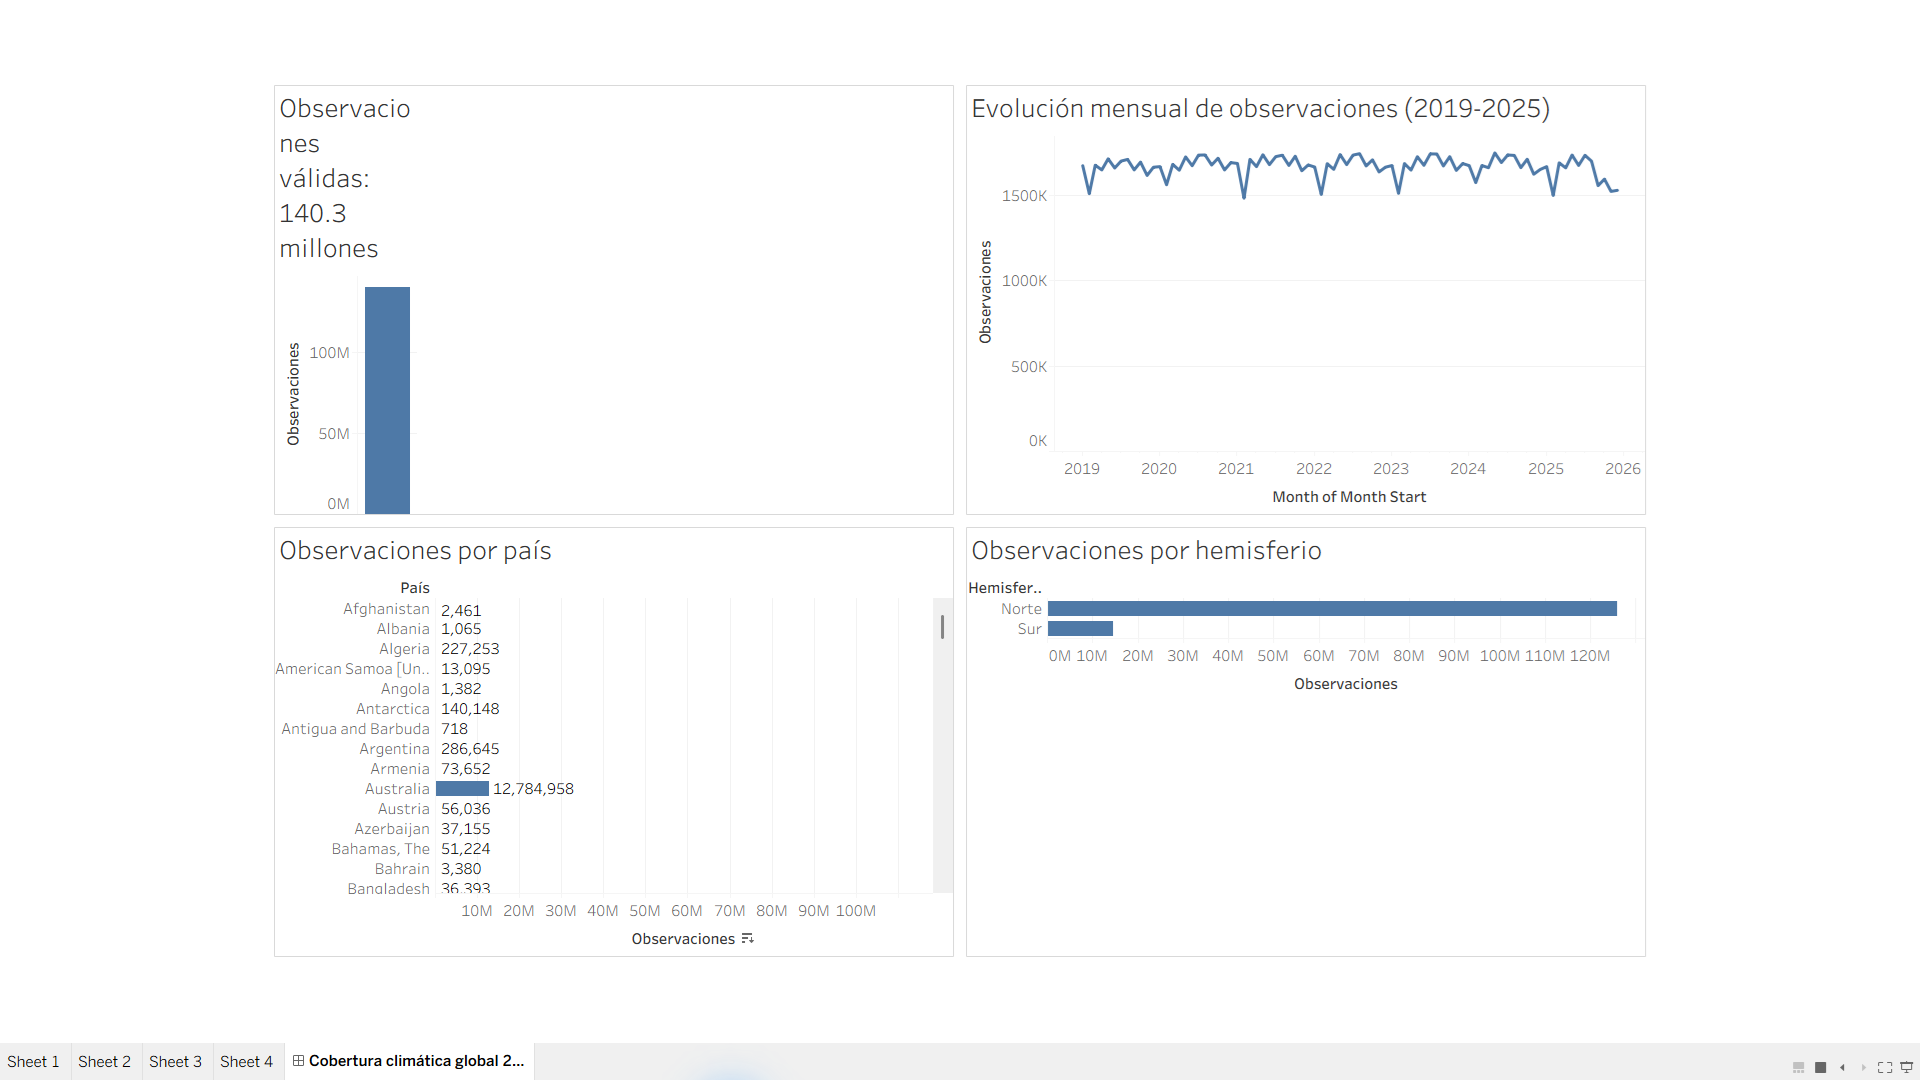

## 12. Conclusiones y límites

Spark permitió leer siete archivos comprimidos, aplicar controles de calidad a 263.4 millones de registros y reducirlos a una capa de 117,590 filas para Tableau. El `Pipeline` dejó reunido el preprocesamiento con la regresión logística y la validación cruzada comparó los parámetros sin tocar el año de prueba.

El AUC-ROC de 0.657 confirma que las variables contienen información, aunque la separación entre clases es moderada. El recall de lluvia de 0.366 es la limitación más clara. Un modelo operativo necesitaría presión atmosférica, humedad, viento, relaciones espaciales entre estaciones y métodos no lineales. También debe considerarse que la densidad de estaciones cambia entre países y años, por lo que el tablero representa tanto el clima como la red de observación.

Este ejercicio cumple el objetivo académico de procesar un volumen real, entrenar un modelo distribuido, evaluarlo con una prueba temporal y preparar una visualización administrada. Sus resultados describen el experimento realizado y no sustituyen los productos de pronóstico de NOAA.